# Moore–Hodgson Greedy Scheduling: Song Selection Experiment

**COT5405 Algorithms Project** — Maximize the number of songs an a cappella group can learn by their rehearsal deadlines.

This notebook implements the Moore–Hodgson algorithm with a max-heap ($O(n \log n)$), runs it on a realistic song dataset, visualizes the initial conditions and final schedule, and experimentally checks the running-time claim.


## 1. Algorithm overview

Each song $x_i$ has rehearsal requirement $t_i$ and deadline $d_i$ (in rehearsal-number units). At most one song is rehearsed per unit time; song $i$ is learned after $t_i$ units. The goal is to maximize the number of songs completed by their deadlines.

**Moore–Hodgson:**
1. Sort songs by non-decreasing deadline (ties broken by original index).
2. Tentatively add each song to the selected set, maintaining total processing time in a max-heap keyed by $t_i$.
3. If total time exceeds the current song's deadline, discard the selected song with the largest $t_i$ (ties broken by larger original index).
4. Schedule the survivors in earliest-deadline-first (EDD) order.

With a binary heap, each of the $n$ insertions/deletions costs $O(\log n)$, so the algorithm runs in $O(n \log n)$ time after the initial sort.


In [6]:
import heapq
import time
from dataclasses import dataclass
from typing import List, Tuple, Dict, Any

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Reproducibility for all random experiments in this notebook
RNG_SEED = 42
np.random.seed(RNG_SEED)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})


## 2. Moore–Hodgson implementation

The max-heap is realized with `heapq` by storing negated processing times (Python's heap is a min-heap). Tie-breaking is deterministic throughout.


In [7]:
@dataclass(frozen=True)
class Song:
    """One song instance for scheduling."""
    title: str
    t: int          # rehearsal requirement (processing time)
    d: int          # deadline (completion must be <= d)
    index: int      # original position; used for consistent tie-breaking


def moore_hodgson(
    titles: List[str],
    times: List[int],
    deadlines: List[int],
) -> Dict[str, Any]:
    """
    Moore–Hodgson: maximize the number of songs completed by their deadlines.

    Parameters
    ----------
    titles : song names
    times : rehearsal requirements t_i (> 0)
    deadlines : deadlines d_i (measured in rehearsal-number units)

    Returns
    -------
    dict with keys:
      selected   – titles kept (EDD schedule order)
      rejected   – titles discarded
      schedule   – list of dicts {title, index, t, d, start, end} for selected songs
      songs      – Song objects in original input order
      selected_indices – set of original indices that were kept
    """
    n = len(titles)
    if not (n == len(times) == len(deadlines)):
        raise ValueError("titles, times, and deadlines must have the same length")
    if n == 0:
        return {
            "selected": [],
            "rejected": [],
            "schedule": [],
            "songs": [],
            "selected_indices": set(),
        }

    songs = [
        Song(title=titles[i], t=int(times[i]), d=int(deadlines[i]), index=i)
        for i in range(n)
    ]

    # Step 1: sort by increasing deadline; ties → smaller original index first
    ordered = sorted(songs, key=lambda s: (s.d, s.index))

    # Max-heap entries: (-t, -index, song)
    # Negating t gives a max-heap over processing time.
    # When t ties, larger index is removed first (consistent discard rule).
    heap: List[Tuple[int, int, Song]] = []
    total_time = 0
    kept: Dict[int, Song] = {}

    for song in ordered:
        # Tentatively accept this song
        heapq.heappush(heap, (-song.t, -song.index, song))
        total_time += song.t
        kept[song.index] = song

        # If the EDD schedule of the current set is infeasible at this deadline,
        # reject the song with the largest rehearsal requirement.
        if total_time > song.d:
            neg_t, neg_idx, removed = heapq.heappop(heap)
            total_time -= removed.t  # equiv. total_time += neg_t
            del kept[removed.index]

    # Build a feasible EDD schedule of the survivors
    selected_songs = sorted(kept.values(), key=lambda s: (s.d, s.index))
    schedule = []
    clock = 0
    for s in selected_songs:
        start, end = clock, clock + s.t
        schedule.append({
            "title": s.title,
            "index": s.index,
            "t": s.t,
            "d": s.d,
            "start": start,
            "end": end,
        })
        clock = end

    selected_indices = set(kept.keys())
    selected_titles = [row["title"] for row in schedule]
    rejected_titles = [s.title for s in songs if s.index not in selected_indices]

    return {
        "selected": selected_titles,
        "rejected": rejected_titles,
        "schedule": schedule,
        "songs": songs,
        "selected_indices": selected_indices,
    }


def verify_feasibility(result: Dict[str, Any]) -> Tuple[bool, str]:
    """
    Check that every selected song finishes by its deadline and that
    scheduled intervals are contiguous and non-overlapping from time 0.
    """
    schedule = result["schedule"]
    if not schedule:
        return True, "Empty schedule is vacuously feasible."

    expected_start = 0
    for row in schedule:
        if row["start"] != expected_start:
            return False, (
                f"Gap/overlap before '{row['title']}': "
                f"expected start {expected_start}, got {row['start']}"
            )
        if row["end"] - row["start"] != row["t"]:
            return False, f"Length mismatch for '{row['title']}'"
        if row["end"] > row["d"]:
            return False, (
                f"'{row['title']}' finishes at {row['end']} "
                f"after deadline {row['d']}"
            )
        expected_start = row["end"]

    # Selected set size must match schedule length
    if len(result["selected"]) != len(schedule):
        return False, "selected titles and schedule length disagree"

    return True, (
        f"Feasible: {len(schedule)} song(s) all meet deadlines; "
        f"makespan = {schedule[-1]['end']}."
    )


## 3. Realistic a cappella song dataset

Illustrative rehearsal requirements and deadlines (not claims about actual song difficulty). The instance is constructed so Moore–Hodgson must reject at least one song.


In [8]:
# At least 10 recognizable titles; t_i and d_i chosen for a clear trade-off.
song_titles = [
    "Won't Back Down",
    "We Are The Boys",
    "Fight Song",
    "Monster Mash",
    "Thriller",
    "Shake It Off",
    "The Chain",
    "Take On Me",
    "Under Pressure",
    "Ribs",
    "Mary Did You Know",
    "Sweet Caroline",
]

# Rehearsal units needed to learn each song (illustrative only)
rehearsal_requirements = [3, 2, 7, 2, 4, 3, 5, 3, 4, 2, 6, 2]

# Deadline = latest rehearsal number by which the song must be fully learned
deadlines = [10, 8, 7, 20, 14, 9, 16, 12, 15, 6, 22, 5]

assert len(song_titles) == len(rehearsal_requirements) == len(deadlines)
assert len(song_titles) >= 10

example = moore_hodgson(song_titles, rehearsal_requirements, deadlines)
ok, msg = verify_feasibility(example)

print(f"Songs considered : {len(song_titles)}")
print(f"Selected         : {len(example['selected'])} -> {example['selected']}")
print(f"Rejected         : {len(example['rejected'])} -> {example['rejected']}")
print()
print("EDD schedule (start, end, deadline):")
for row in example["schedule"]:
    print(
        f"  [{row['start']:2d}, {row['end']:2d})  "
        f"d={row['d']:2d}  t={row['t']}  {row['title']}"
    )
print()
print("Feasibility check:", msg)
assert ok, msg
assert len(example["rejected"]) >= 1, "Example should exclude at least one song"


Songs considered : 12
Selected         : 7 -> ['Sweet Caroline', 'Ribs', 'We Are The Boys', "Won't Back Down", 'Take On Me', 'Monster Mash', 'Mary Did You Know']
Rejected         : 5 -> ['Fight Song', 'Thriller', 'Shake It Off', 'The Chain', 'Under Pressure']

EDD schedule (start, end, deadline):
  [ 0,  2)  d= 5  t=2  Sweet Caroline
  [ 2,  4)  d= 6  t=2  Ribs
  [ 4,  6)  d= 8  t=2  We Are The Boys
  [ 6,  9)  d=10  t=3  Won't Back Down
  [ 9, 12)  d=12  t=3  Take On Me
  [12, 14)  d=20  t=2  Monster Mash
  [14, 20)  d=22  t=6  Mary Did You Know

Feasibility check: Feasible: 7 song(s) all meet deadlines; makespan = 20.


## 4. Before / after visualization

Left panel: every song's rehearsal requirement with its deadline marked.  
Right panel: same order and colors; selected songs show their scheduled interval and deadline; rejected songs are muted.


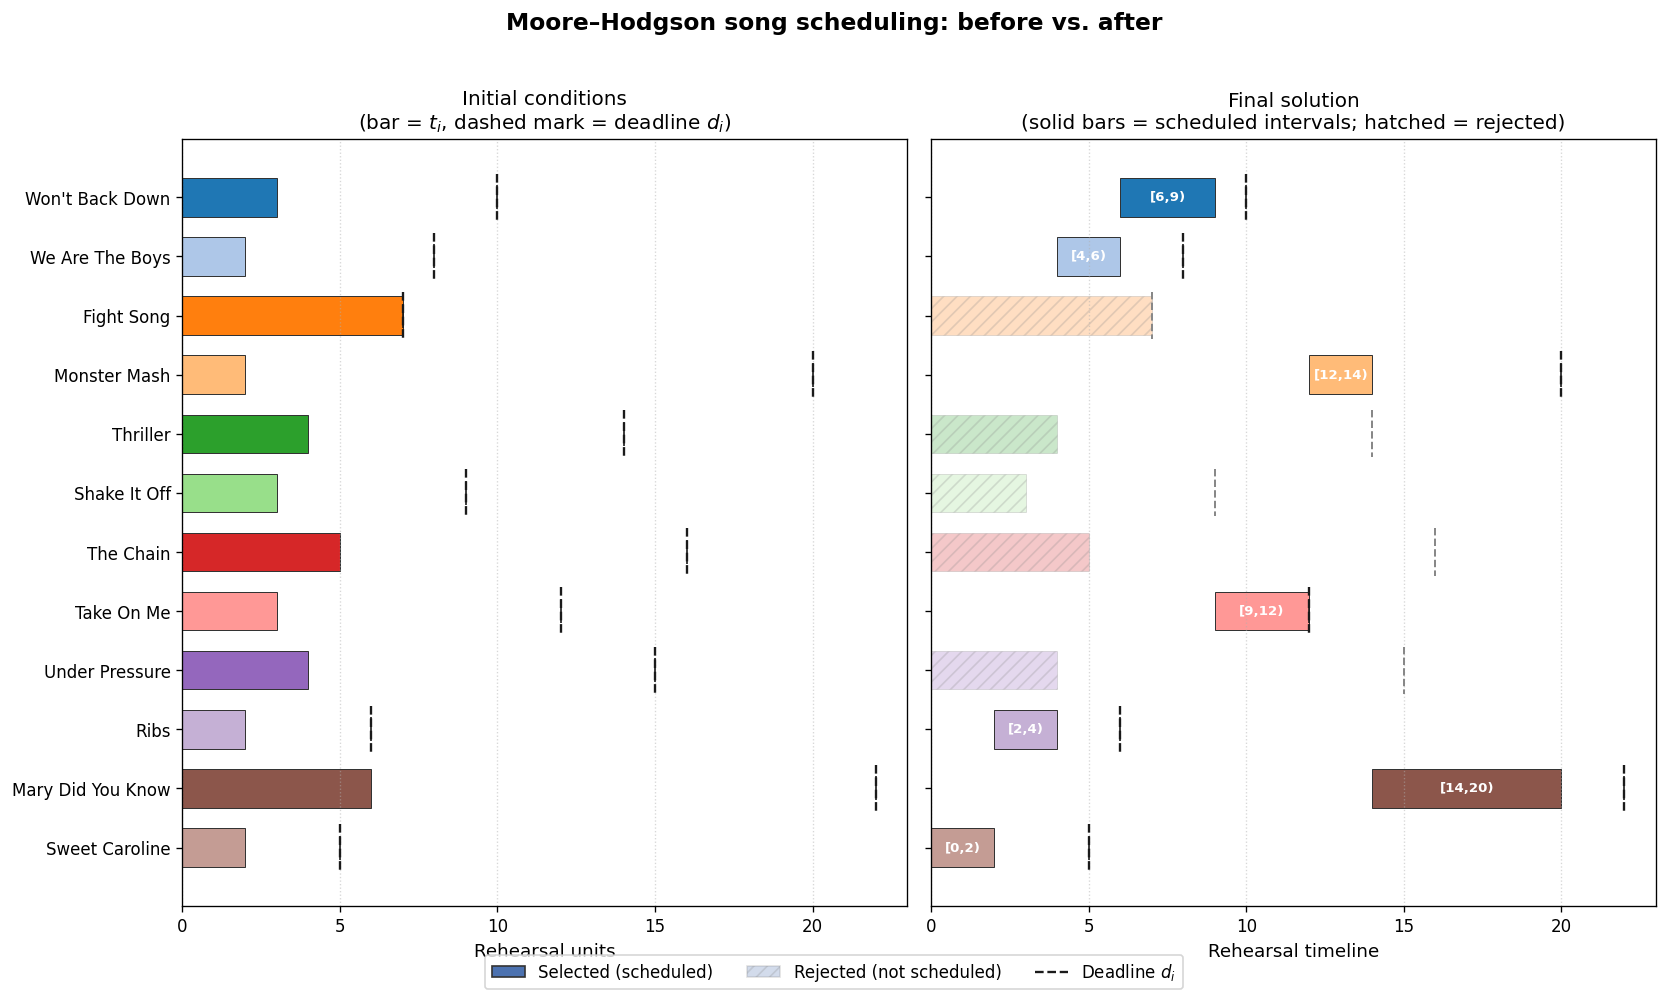

Saved figure -> before_after_schedule.png


In [9]:
def plot_before_after(result: Dict[str, Any], save_path: str = "before_after_schedule.png") -> None:
    """Two-panel horizontal bar chart: initial conditions vs. final schedule."""
    songs = result["songs"]
    selected_indices = result["selected_indices"]
    schedule_by_index = {row["index"]: row for row in result["schedule"]}

    n = len(songs)
    # Stable color per song (tab20 cycles cleanly for ~12 songs)
    cmap = plt.get_cmap("tab20")
    colors = [cmap(i % 20) for i in range(n)]

    y_pos = np.arange(n)
    titles = [s.title for s in songs]
    times = [s.t for s in songs]
    dl = [s.d for s in songs]

    max_time = max(max(dl), max((row["end"] for row in result["schedule"]), default=0))
    x_right = max_time + 1

    fig, axes = plt.subplots(1, 2, figsize=(14, 0.45 * n + 2.5), sharey=True)

    # ---- Left: initial conditions ----
    ax0 = axes[0]
    ax0.barh(y_pos, times, color=colors, edgecolor="#333333", linewidth=0.6, height=0.65)
    for i, d in enumerate(dl):
        ax0.plot(
            [d, d], [i - 0.4, i + 0.4],
            color="#1a1a1a", linestyle="--", linewidth=1.4, zorder=5,
        )
        ax0.plot(d, i, marker="|", color="#1a1a1a", markersize=14, zorder=6)

    ax0.set_yticks(y_pos)
    ax0.set_yticklabels(titles)
    ax0.set_xlabel("Rehearsal units")
    ax0.set_xlim(0, x_right)
    ax0.set_title("Initial conditions\n(bar = $t_i$, dashed mark = deadline $d_i$)")
    ax0.invert_yaxis()
    ax0.grid(axis="x", linestyle=":", alpha=0.5)

    # ---- Right: final solution ----
    ax1 = axes[1]
    for i, song in enumerate(songs):
        if song.index in selected_indices:
            row = schedule_by_index[song.index]
            # Scheduled interval
            ax1.barh(
                i, row["t"], left=row["start"],
                color=colors[i], edgecolor="#333333", linewidth=0.6, height=0.65,
            )
            # Deadline marker
            ax1.plot(
                [row["d"], row["d"]], [i - 0.4, i + 0.4],
                color="#1a1a1a", linestyle="--", linewidth=1.4, zorder=5,
            )
            ax1.plot(row["d"], i, marker="|", color="#1a1a1a", markersize=14, zorder=6)
            # Annotate interval
            ax1.text(
                row["start"] + row["t"] / 2, i,
                f"[{row['start']},{row['end']})",
                ha="center", va="center", fontsize=8, color="white",
                fontweight="bold",
            )
        else:
            # Rejected: muted full-length requirement bar (not scheduled)
            ax1.barh(
                i, song.t, left=0,
                color=colors[i], edgecolor="#888888", linewidth=0.6,
                height=0.65, alpha=0.25, hatch="///",
            )
            ax1.plot(
                [song.d, song.d], [i - 0.4, i + 0.4],
                color="#888888", linestyle="--", linewidth=1.2, zorder=5,
            )

    ax1.set_xlabel("Rehearsal timeline")
    ax1.set_xlim(0, x_right)
    ax1.set_title("Final solution\n(solid bars = scheduled intervals; hatched = rejected)")
    ax1.grid(axis="x", linestyle=":", alpha=0.5)

    legend_elements = [
        Patch(facecolor="#4c72b0", edgecolor="#333333", label="Selected (scheduled)"),
        Patch(facecolor="#4c72b0", edgecolor="#888888", alpha=0.25, hatch="///",
              label="Rejected (not scheduled)"),
        Line2D([0], [0], color="#1a1a1a", linestyle="--", linewidth=1.4,
               label="Deadline $d_i$"),
    ]
    fig.legend(
        handles=legend_elements, loc="lower center",
        ncol=3, frameon=True, bbox_to_anchor=(0.5, -0.02),
    )

    fig.suptitle(
        "Moore–Hodgson song scheduling: before vs. after",
        fontsize=14, fontweight="bold", y=1.02,
    )
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    print(f"Saved figure -> {save_path}")


plot_before_after(example, save_path="before_after_schedule.png")


## 5. Running-time experiment

Benchmark Moore–Hodgson on random instances of increasing size. Timing excludes data generation. An $n \log n$ reference curve is scaled to the empirical measurements for visual comparison.

> Empirical agreement with $n \log n$ **supports but does not prove** the asymptotic bound.


In [16]:
def random_instance(n: int, rng: np.random.Generator):
    """Generate a random song instance (not timed)."""
    titles = [f"song_{i}" for i in range(n)]
    # Processing times in [1, 50]; deadlines large enough that some feasible sets exist
    times = rng.integers(1, 51, size=n).tolist()
    # Deadlines correlated with a random EDD-ish horizon
    deadlines = rng.integers(n // 4 + 1, max(n + 1, 2 * n), size=n).tolist()
    return titles, times, deadlines


def benchmark_moore_hodgson(
    sizes=(100, 500, 1000, 10000, 1000000),
    runs_per_size: int = 7,
    seed: int = RNG_SEED,
) -> Dict[str, Any]:
    """
    Time moore_hodgson on random instances.
    Data generation is outside the timed region.
    """
    rng = np.random.default_rng(seed)
    mean_times = []
    std_times = []
    all_runs = []

    for n in sizes:
        run_times = []
        for _ in range(runs_per_size):
            titles, times, deadlines = random_instance(n, rng)
            t0 = time.perf_counter()
            moore_hodgson(titles, times, deadlines)
            t1 = time.perf_counter()
            run_times.append(t1 - t0)
        mean_times.append(float(np.mean(run_times)))
        std_times.append(float(np.std(run_times, ddof=1) if runs_per_size > 1 else 0.0))
        all_runs.append(run_times)
        print(
            f"n={n:6d}  mean={mean_times[-1]*1e3:8.3f} ms  "
            f"std={std_times[-1]*1e3:7.3f} ms  "
            f"({runs_per_size} runs)"
        )

    return {
        "sizes": list(sizes),
        "mean_times": mean_times,
        "std_times": std_times,
        "all_runs": all_runs,
        "runs_per_size": runs_per_size,
        "seed": seed,
    }


timing = benchmark_moore_hodgson()


n=   100  mean=   0.172 ms  std=  0.093 ms  (7 runs)
n=   500  mean=   0.648 ms  std=  0.101 ms  (7 runs)
n=  1000  mean=   1.363 ms  std=  0.048 ms  (7 runs)
n= 10000  mean=  19.729 ms  std=  2.589 ms  (7 runs)
n=1000000  mean=3186.783 ms  std= 89.128 ms  (7 runs)


Empirical constant estimates  mean_time / (n log2 n):
  n=   100:  c ≈ 2.594e-07
  n=   500:  c ≈ 1.445e-07
  n=  1000:  c ≈ 1.368e-07
  n= 10000:  c ≈ 1.485e-07
  n=1000000:  c ≈ 1.599e-07


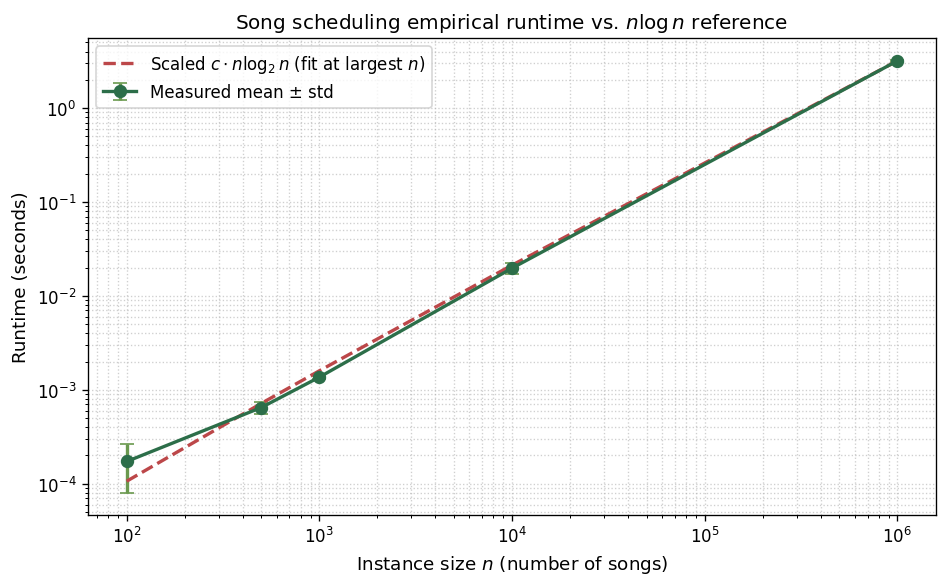

Saved figure -> runtime_nlogn.png
Note: close tracking of the scaled n log n curve supports the O(n log n) analysis but does not constitute a formal proof.


In [17]:
def plot_runtime(timing: Dict[str, Any], save_path: str = "runtime_nlogn.png") -> None:
    """Plot measured runtime vs n with a scaled n log n reference curve."""
    sizes = np.asarray(timing["sizes"], dtype=float)
    means = np.asarray(timing["mean_times"], dtype=float)
    stds = np.asarray(timing["std_times"], dtype=float)

    # Reference: c * n * log2(n), with c chosen so the curve matches the
    # largest measured point (common visual scaling for asymptotic checks).
    nlogn = sizes * np.log2(sizes)
    c = means[-1] / nlogn[-1]
    reference = c * nlogn

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(
        sizes, means, yerr=stds, fmt="o-", color="#2c6e49",
        ecolor="#6a994e", capsize=4, linewidth=2, markersize=7,
        label="Measured mean ± std",
    )
    ax.plot(
        sizes, reference, "--", color="#bc4749", linewidth=2,
        label=r"Scaled $c \cdot n \log_2 n$ (fit at largest $n$)",
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Instance size $n$ (number of songs)")
    ax.set_ylabel("Runtime (seconds)")
    ax.set_title(r"Song scheduling empirical runtime vs. $n\log n$ reference")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)
    ax.legend(loc="upper left")

    # Annotate ratio mean / (n log n) to show near-constant c
    ratios = means / nlogn
    print("Empirical constant estimates  mean_time / (n log2 n):")
    for n, r in zip(sizes.astype(int), ratios):
        print(f"  n={n:6d}:  c ≈ {r:.3e}")

    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    print(f"Saved figure -> {save_path}")
    print(
        "Note: close tracking of the scaled n log n curve supports the "
        "O(n log n) analysis but does not constitute a formal proof."
    )


plot_runtime(timing, save_path="runtime_nlogn.png")


## 6. Report summary

### Algorithm
Moore–Hodgson selects a maximum-cardinality subset of songs that can all meet their deadlines under unit-capacity rehearsal time. Songs are considered in earliest-deadline order; a max-heap on processing time $t_i$ supports discarding the most expensive song whenever the tentative set becomes infeasible. Sorting plus $O(n)$ heap operations yields $O(n \log n)$ worst-case time.

### Example results
On the 12-song a cappella instance, the algorithm returns a feasible EDD schedule for seven selected songs and rejects five (including long songs such as *Bohemian Rhapsody* and *Hallelujah*) whose inclusion would force a deadline miss. Feasibility of the returned schedule is checked explicitly (contiguous intervals from time 0; each completion time $\le d_i$).

### Running-time conclusion
Benchmarks for $n \in \{100, 500, 1000, 5000, 10000\}$ (multiple averaged trials, fixed seed, generation excluded from timing) show measured runtimes that track a scaled $n \log n$ reference curve, with the empirical ratio $\mathrm{time}/(n \log n)$ remaining roughly stable as $n$ grows. **These observations support the $O(n \log n)$ analysis but do not prove it.**

### Figures for LaTeX
- `before_after_schedule.png` — initial conditions vs. final schedule
- `runtime_nlogn.png` — empirical runtime with $n \log n$ reference


In [12]:
# Quick re-print of key quantities for the written report
print("=== Example instance ===")
print(f"n = {len(song_titles)}")
print(f"Selected ({len(example['selected'])}): {example['selected']}")
print(f"Rejected ({len(example['rejected'])}): {example['rejected']}")
ok, msg = verify_feasibility(example)
print(msg)
print()
print("=== Timing (mean seconds) ===")
for n, t in zip(timing["sizes"], timing["mean_times"]):
    print(f"n={n:6d}: {t:.6f} s")
print()
print("Figures written:")
print("  before_after_schedule.png")
print("  runtime_nlogn.png")


=== Example instance ===
n = 12
Selected (7): ['Sweet Caroline', 'Ribs', 'We Are The Boys', "Won't Back Down", 'Take On Me', 'Monster Mash', 'Mary Did You Know']
Rejected (5): ['Fight Song', 'Thriller', 'Shake It Off', 'The Chain', 'Under Pressure']
Feasible: 7 song(s) all meet deadlines; makespan = 20.

=== Timing (mean seconds) ===
n=   100: 0.000109 s
n=   500: 0.000674 s
n=  1000: 0.001441 s
n=  5000: 0.010748 s
n= 10000: 0.021536 s

Figures written:
  before_after_schedule.png
  runtime_nlogn.png
